In [1]:
import os

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import scanpy as sc

In [2]:
st_data_folder_path = '/lustre/scratch126/cellgen/lotfollahi/DATASETS'
st_data_silver_folder_path = f'{st_data_folder_path}/silver'
artifacts_folder_path = '/nfs/team361/sb75/stjepa-reproducibility/artifacts'

In [3]:
# General params
dataset_name = 'mmb0-1b_smb1-1b_1p'
batches = ['harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes',
           'harmonised_starmap_plus_mouse_cns_batch15_shared_genes']
niche_key = 'tissue_region'
label_keys = [niche_key]
species = 'mouse'
n_neighs = 10
spot_sizes = {'MERFISH': 20,
              'STARmap PLUS': 100}
batch_key = 'batch'
n_pcs = None

57.67001449275363
6754.784312267653
27.659048275861984
4988.507046153837
0.0
4960.847997877975
0.0
6697.1142977749


/tmp/ipykernel_597204/2559616770.py:29: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_starmap, spot_size=20)


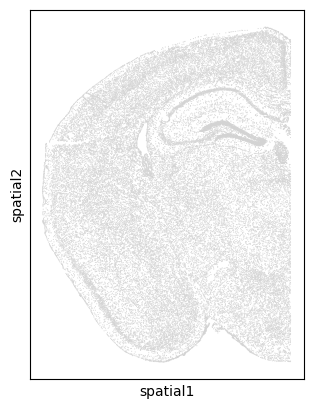

/lustre/scratch126/cellgen/lotfollahi/DATASETS/silver/mmb0-1b_smb1-1b_1p_coord_aligned/harmonised_starmap_plus_mouse_cns_batch15_shared_genes.h5ad


In [5]:
# Load STARmap PLUS data
dataset_name = 'mmb0-1b_smb1-1b_1p'
file_path = f'/lustre/scratch126/cellgen/lotfollahi/DATASETS/silver/{dataset_name}/harmonised_starmap_plus_mouse_cns_batch15_shared_genes.h5ad'
adata_starmap = sc.read_h5ad(file_path)

# STARmap PLUS: voxel coordinates -> microns
# Voxel size: 194 x 194 x 345 nm³
adata_starmap.obsm['spatial'] = adata_starmap.obsm['spatial'] * 0.194  # XY voxel size in µm

print(min(adata_starmap.obsm['spatial'][:, 0]))
print(max(adata_starmap.obsm['spatial'][:, 0]))
print(min(adata_starmap.obsm['spatial'][:, 1]))
print(max(adata_starmap.obsm['spatial'][:, 1]))

adata_starmap.obsm['spatial'][:, 1] -= min(adata_starmap.obsm['spatial'][:, 1])
adata_starmap.obsm['spatial'][:, 0] -= min(adata_starmap.obsm['spatial'][:, 0])

tmp0 = adata_starmap.obsm['spatial'][:, 0].copy()
tmp1 = adata_starmap.obsm['spatial'][:, 1].copy()

adata_starmap.obsm['spatial'][:, 0] = tmp1
adata_starmap.obsm['spatial'][:, 1] = tmp0

print(min(adata_starmap.obsm['spatial'][:, 0]))
print(max(adata_starmap.obsm['spatial'][:, 0]))
print(min(adata_starmap.obsm['spatial'][:, 1]))
print(max(adata_starmap.obsm['spatial'][:, 1]))

sc.pl.spatial(adata_starmap, spot_size=20)

print(file_path.replace(dataset_name, f'{dataset_name}_coord_aligned'))
os.makedirs(f'/lustre/scratch126/cellgen/lotfollahi/DATASETS/silver/{dataset_name}_coord_aligned', exist_ok=True)
adata_starmap.write(file_path.replace(dataset_name, f'{dataset_name}_coord_aligned'))

3989.7082325792526
9272.842763707886
-73734.8661633768
-67903.21487925046
0.0
5283.134531128633
0.0
5831.651284126347


/tmp/ipykernel_597204/2758534195.py:24: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_merfish, spot_size=20)


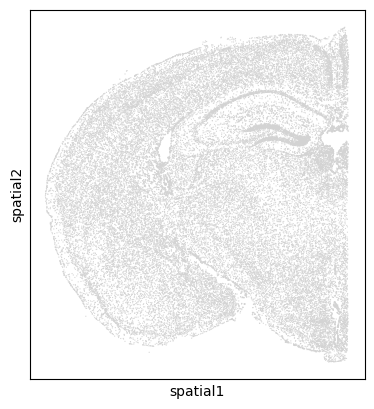

/lustre/scratch126/cellgen/lotfollahi/DATASETS/silver/mmb0-1b_smb1-1b_1p_coord_aligned/harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes.h5ad


In [7]:
# Load MERFISH data
dataset_name = 'mmb0-1b_smb1-1b_1p'
file_path = f'/lustre/scratch126/cellgen/lotfollahi/DATASETS/silver/{dataset_name}/harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes.h5ad'
adata_merfish = sc.read_h5ad(file_path)

# MERFISH: already in microns, no conversion needed
# adata_merfish.obsm['spatial'] is ready to use as-is

print(min(adata_merfish.obsm['spatial'][:, 0]))
print(max(adata_merfish.obsm['spatial'][:, 0]))
print(min(adata_merfish.obsm['spatial'][:, 1]))
print(max(adata_merfish.obsm['spatial'][:, 1]))

adata_merfish.obsm['spatial'][:, 1] = -adata_merfish.obsm['spatial'][:, 1]

adata_merfish.obsm['spatial'][:, 1] -= min(adata_merfish.obsm['spatial'][:, 1])
adata_merfish.obsm['spatial'][:, 0] -= min(adata_merfish.obsm['spatial'][:, 0])

print(min(adata_merfish.obsm['spatial'][:, 0]))
print(max(adata_merfish.obsm['spatial'][:, 0]))
print(min(adata_merfish.obsm['spatial'][:, 1]))
print(max(adata_merfish.obsm['spatial'][:, 1]))

sc.pl.spatial(adata_merfish, spot_size=20)

print(file_path.replace(dataset_name, f'{dataset_name}_coord_aligned'))
os.makedirs(f'/lustre/scratch126/cellgen/lotfollahi/DATASETS/silver/{dataset_name}_coord_aligned', exist_ok=True)
adata_merfish.write(file_path.replace(dataset_name, f'{dataset_name}_coord_aligned'))

57.67001449275363
6754.784312267653
27.659048275861984
4988.507046153837
0.0
4960.847997877975
0.0
6697.1142977749


/tmp/ipykernel_597204/2343525887.py:29: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_starmap, spot_size=20)


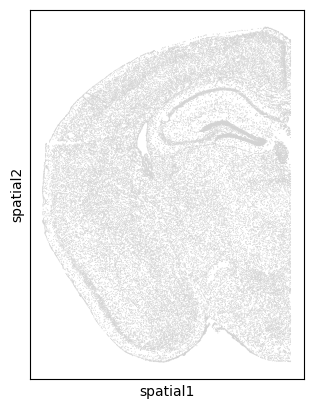

/lustre/scratch126/cellgen/lotfollahi/DATASETS/silver/mmb0-1b_smb1-1b_2p_coord_aligned/harmonised_starmap_plus_mouse_cns_batch15.h5ad


In [6]:
# Load STARmap PLUS data
dataset_name = 'mmb0-1b_smb1-1b_2p'
file_path = f'/lustre/scratch126/cellgen/lotfollahi/DATASETS/silver/{dataset_name}/harmonised_starmap_plus_mouse_cns_batch15.h5ad'
adata_starmap = sc.read_h5ad(file_path)

# STARmap PLUS: voxel coordinates -> microns
# Voxel size: 194 x 194 x 345 nm³
adata_starmap.obsm['spatial'] = adata_starmap.obsm['spatial'] * 0.194  # XY voxel size in µm

print(min(adata_starmap.obsm['spatial'][:, 0]))
print(max(adata_starmap.obsm['spatial'][:, 0]))
print(min(adata_starmap.obsm['spatial'][:, 1]))
print(max(adata_starmap.obsm['spatial'][:, 1]))

adata_starmap.obsm['spatial'][:, 1] -= min(adata_starmap.obsm['spatial'][:, 1])
adata_starmap.obsm['spatial'][:, 0] -= min(adata_starmap.obsm['spatial'][:, 0])

tmp0 = adata_starmap.obsm['spatial'][:, 0].copy()
tmp1 = adata_starmap.obsm['spatial'][:, 1].copy()

adata_starmap.obsm['spatial'][:, 0] = tmp1
adata_starmap.obsm['spatial'][:, 1] = tmp0

print(min(adata_starmap.obsm['spatial'][:, 0]))
print(max(adata_starmap.obsm['spatial'][:, 0]))
print(min(adata_starmap.obsm['spatial'][:, 1]))
print(max(adata_starmap.obsm['spatial'][:, 1]))

sc.pl.spatial(adata_starmap, spot_size=20)

print(file_path.replace(dataset_name, f'{dataset_name}_coord_aligned'))
os.makedirs(f'/lustre/scratch126/cellgen/lotfollahi/DATASETS/silver/{dataset_name}_coord_aligned', exist_ok=True)
adata_starmap.write(file_path.replace(dataset_name, f'{dataset_name}_coord_aligned'))

3989.7082325792526
9272.842763707886
-73735.32413347968
-67903.21487925046
0.0
5283.134531128633
0.0
5832.109254229217


/tmp/ipykernel_597204/3326506389.py:24: FutureWarning: Use `squidpy.pl.spatial_scatter` instead.
  sc.pl.spatial(adata_merfish, spot_size=20)


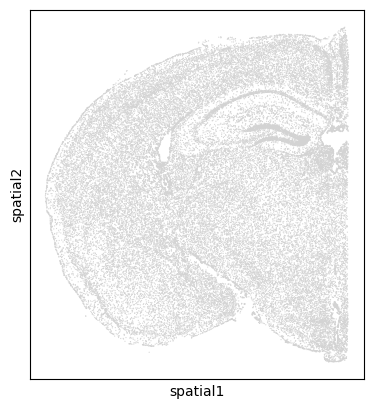

/lustre/scratch126/cellgen/lotfollahi/DATASETS/silver/mmb0-1b_smb1-1b_2p_coord_aligned/harmonised_merfish_mouse_brain_239-batch_batch82.h5ad


In [8]:
# Load MERFISH data
dataset_name = 'mmb0-1b_smb1-1b_2p'
file_path = f'/lustre/scratch126/cellgen/lotfollahi/DATASETS/silver/{dataset_name}/harmonised_merfish_mouse_brain_239-batch_batch82.h5ad'
adata_merfish = sc.read_h5ad(file_path)

# MERFISH: already in microns, no conversion needed
# adata_merfish.obsm['spatial'] is ready to use as-is

print(min(adata_merfish.obsm['spatial'][:, 0]))
print(max(adata_merfish.obsm['spatial'][:, 0]))
print(min(adata_merfish.obsm['spatial'][:, 1]))
print(max(adata_merfish.obsm['spatial'][:, 1]))

adata_merfish.obsm['spatial'][:, 1] = -adata_merfish.obsm['spatial'][:, 1]

adata_merfish.obsm['spatial'][:, 1] -= min(adata_merfish.obsm['spatial'][:, 1])
adata_merfish.obsm['spatial'][:, 0] -= min(adata_merfish.obsm['spatial'][:, 0])

print(min(adata_merfish.obsm['spatial'][:, 0]))
print(max(adata_merfish.obsm['spatial'][:, 0]))
print(min(adata_merfish.obsm['spatial'][:, 1]))
print(max(adata_merfish.obsm['spatial'][:, 1]))

sc.pl.spatial(adata_merfish, spot_size=20)

print(file_path.replace(dataset_name, f'{dataset_name}_coord_aligned'))
os.makedirs(f'/lustre/scratch126/cellgen/lotfollahi/DATASETS/silver/{dataset_name}_coord_aligned', exist_ok=True)
adata_merfish.write(file_path.replace(dataset_name, f'{dataset_name}_coord_aligned'))

In [23]:
# Load adata batches and concatenate for inference
adata_list = []

for subdir, _, files in os.walk(f'{st_data_silver_folder_path}/{dataset_name}'):
    for file_idx, file in enumerate(files):
        if file.endswith('.h5ad') & any(batch in file for batch in batches):
            file_path = os.path.join(subdir, file)
            adata = sc.read_h5ad(file_path)

            print(file)

            if file == 'harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes.h5ad':
                adata.obs[niche_key] = adata.obs['ccf_region_name']
                adata.obs[batch_key] = file.replace('.h5ad', '')
            elif file == 'harmonised_starmap_plus_mouse_cns_batch15_shared_genes.h5ad':
                adata.obs[niche_key] = adata.obs['Sub_molecular_tissue_region']
                adata.obs[batch_key] = file.replace('.h5ad', '')                

            # Filter cells without niche labels
            adata = adata[~adata.obs[niche_key].isna()]
            print(adata.obs.columns)
            adata_list.append(adata)

adata = ad.concat(adata_list, join='outer', index_unique=None)

harmonised_merfish_mouse_brain_239-batch_batch82_shared_genes.h5ad
Index(['donor_id', 'brain_section_label', 'major_brain_region',
       'ccf_region_name', 'cell_type', 'cell_id', 'n_genes',
       'nichecompass_latent_cluster', 'tissue_region', 'batch'],
      dtype='object')
harmonised_starmap_plus_mouse_cns_batch15_shared_genes.h5ad
Index(['Main_molecular_cell_type', 'Sub_molecular_cell_type',
       'Main_molecular_tissue_region', 'Sub_molecular_tissue_region',
       'Molecular_spatial_cell_type', 'dataset', 'cell_type',
       'cell_type_ontology_term_id', 'n_genes', 'cell_id',
       'nichecompass_latent_cluster', 'tissue_region', 'batch'],
      dtype='object')


/nfs/team361/sb75/.venvs/stjepa_v1/lib/python3.10/site-packages/anndata/_core/merge.py:1434: UserWarning: Only some AnnData objects have `.raw` attribute, not concatenating `.raw` attributes.
  warn(


In [24]:
# MERFISH: already in microns, no conversion needed
# adata_list[0].obsm['spatial'] is ready to use as-is

# STARmap PLUS: voxel coordinates -> microns
# Voxel size: 194 x 194 x 345 nm³
adata_list[1].obsm['spatial'] = adata_list[1].obsm['spatial'] * 0.194  # XY voxel size in µm

/tmp/ipykernel_678648/2025512999.py:6: ImplicitModificationWarning: Setting element `.obsm['spatial']` of view, initializing view as actual.
  adata_list[1].obsm['spatial'] = adata_list[1].obsm['spatial'] * 0.194  # XY voxel size in µm


/tmp/ipykernel_678648/863037477.py:4: ImplicitModificationWarning: Setting element `.obsm['spatial']` of view, initializing view as actual.
  adata_list[0].obsm['spatial'] = coords0
/tmp/ipykernel_678648/863037477.py:13: ImplicitModificationWarning: Setting element `.obsm['spatial']` of view, initializing view as actual.
  a.obsm['spatial'] = coords


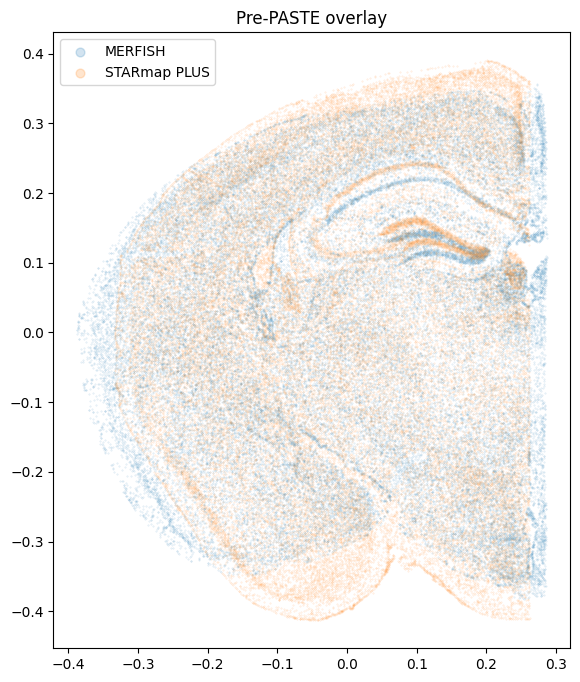

In [20]:
# ── 1. Flip MERFISH y-axis (raw coords have inverted y) ──
coords0 = adata_list[0].obsm['spatial'].copy().astype(float)
coords0[:, 1] = -coords0[:, 1]
adata_list[0].obsm['spatial'] = coords0

# ── 2. Center and normalize both to unit diagonal ──
for a in adata_list:
    coords = a.obsm['spatial'].copy().astype(float)
    coords -= coords.mean(axis=0)
    diag = np.sqrt((coords[:, 0].max() - coords[:, 0].min())**2 +
                   (coords[:, 1].max() - coords[:, 1].min())**2)
    coords /= diag
    a.obsm['spatial'] = coords

# ── 3. Rotate and flip ──
def apply_rotation(coords, angle_deg, flip=None):
    x, y = coords[:, 0], coords[:, 1]
    theta = np.radians(angle_deg)
    x_rot = x * np.cos(theta) - y * np.sin(theta)
    y_rot = x * np.sin(theta) + y * np.cos(theta)
    if flip == 'x':
        x_rot = -x_rot
    elif flip == 'y':
        y_rot = -y_rot
    return np.column_stack([x_rot, y_rot])

adata_list[0].obsm['spatial'] = apply_rotation(adata_list[0].obsm['spatial'], 180, flip='x')
adata_list[1].obsm['spatial'] = apply_rotation(adata_list[1].obsm['spatial'], 270)

# ── 4. Verify overlay ──
fig, ax = plt.subplots(figsize=(8, 8))
colors = ['tab:blue', 'tab:orange']
labels = ['MERFISH', 'STARmap PLUS']
for i, a in enumerate(adata_list):
    c = a.obsm['spatial']
    ax.scatter(c[:, 0], c[:, 1], s=0.1, alpha=0.2, c=colors[i], label=labels[i])
ax.set_aspect('equal')
ax.legend(markerscale=20)
ax.set_title('Pre-PASTE overlay')
plt.show()

In [22]:
adata.obsm['spatial']

array([[  4012.72324225, -70683.34673359],
       [  4049.74477774, -70565.29519162],
       [  4027.89098961, -70540.54826536],
       ...,
       [ 34106.06818182,  25049.78030303],
       [ 34648.2       ,  24484.69411765],
       [ 34753.99038462,  25492.13461538]], shape=(85704, 2))